# Буткемп, электронный relative-value трейдинг, день 23 — toxicity, liquidation regimes и hedge control

Задание с лекции 29.10. Токсичность — это состояние потока, а самый токсичный поток — вынужденные ликвидации. План такой: измерить markout по шести кондиционерам (OFI, глубина свипа, волатильность, интенсивность ликвидаций, позиция в очереди, возраст котировки), собрать score с унивариативными весами и **проверить его на held-out** (decile chart — оцениваемый Task 2), найти каскады, построить детектор из четырёх состояний, переключение пяти режимов и urgency хеджа.

Данные: BTCUSDT Bybit, 100-мс top-of-book и трейды за 2026-07-01 (train) и 2026-07-02 (test), окна по 12:00–14:00 UTC. Ликвидационного фида нет, поэтому интенсивность ликвидаций строим как прокси по крупным агрессивным свипам и прыжкам цены. Это именно ограничение, а не «настоящий» liq feed.


## Fill log и кондиционеры

Каждые 5 с ставим bid/ask на touch и держим 10 с. Филл — первый трейд, который бьёт в нашу цену; вероятность $p=\min(1,\text{size}/\text{queue})$. Markout считаем через 10 с от цены филла. На момент филла снимаем шесть кондиционеров:
- OFI — signed aggressive volume за 1 с;
- sweep depth — размер филлящего трейда / очередь;
- volatility — rolling σ за 10 с;
- liq intensity — прокси: сумма агрессивного объёма в 1-с окне при |return| > 3σ;
- queue position — размер touch-очереди;
- quote age — секунды с постановки.


In [1]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore'); pd.set_option('display.width',180)
D='/Users/b.kotov/Downloads/'; tick=0.1
con=duckdb.connect()
def load(day):
    d0=f'2026-07-0{day} 12:00:00+00'; d1=f'2026-07-0{day} 14:00:00+00'
    p=con.execute(f"""SELECT event_time, mid, best_bid, best_ask, best_bid_amount, best_ask_amount
      FROM read_parquet('{D}l2_executable_quotes_100ms_10000.parquet') WHERE asset='BTC' AND exchange='Bybit'
      AND event_time>=TIMESTAMPTZ '{d0}' AND event_time<TIMESTAMPTZ '{d1}' ORDER BY event_time""").df().reset_index(drop=True)
    t=con.execute(f"""SELECT event_time, price, amount FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
      WHERE symbol='BTCUSDT' AND event_time>=TIMESTAMPTZ '{d0}' AND event_time<TIMESTAMPTZ '{d1}' ORDER BY event_time""").df()
    return p,t
def prep(day):
    p,t=load(day); n=len(p); T=np.array(p.event_time.astype('int64')); mid=p.mid.values; bb=p.best_bid.values; ba=p.best_ask.values; bs=p.best_bid_amount.values; as_=p.best_ask_amount.values
    tt=np.array(t.event_time.astype('int64')); idx=np.searchsorted(T,tt,'right')-1
    ok=(idx>=0)&(idx<n); idx=idx[ok]; t=t.iloc[np.where(ok)[0]].reset_index(drop=True); px=t.price.values; amt=t.amount.values
    sgn=np.where(np.abs(px-ba[idx])<=tick/2,1,np.where(np.abs(px-bb[idx])<=tick/2,-1,0))
    tv=np.zeros(n); np.add.at(tv,idx,sgn*amt); flow=np.cumsum(tv)
    sig=pd.Series(np.diff(mid,prepend=mid[0])/tick).rolling(100,min_periods=50).std().values
    ret10=np.zeros(n); ret10[10:]=(mid[10:]-mid[:-10])/tick
    # liquidation proxy: aggressive volume when |10-step return| > 3 sigma
    big=np.abs(ret10)>3*np.maximum(sig,1e-9)*np.sqrt(10)
    liq=np.zeros(n)
    for j in range(len(px)):
        if big[idx[j]]: liq[idx[j]]+=amt[j]
    liq=pd.Series(liq).rolling(10,min_periods=1).sum().values
    rows=[]
    for i in range(0,n-150,50):
        for side,price,queue in ((1,bb[i],bs[i]),(-1,ba[i],as_[i])):
            j0=np.searchsorted(idx,i,'left'); j1=np.searchsorted(idx,i+100,'left')
            kk=idx[j0:j1]; ppx=px[j0:j1]
            m=(np.abs(ppx-price)<=tick/2)
            w=np.where(m)[0]
            if len(w)==0: continue
            j=w[0]; k=kk[j]
            if k+100>=n: continue
            pp=min(1,amt[j]/max(queue,1e-9))
            mo=(mid[k+100]-price)/tick if side==1 else (price-mid[k+100])/tick
            ofi=flow[k]-flow[max(k-10,0)]
            rows.append({'day':day,'side':side,'p':pp,'mark':mo,'ofi':ofi,'sweep':amt[j]/max(queue,1e-9),
                         'vol':sig[k],'liq':liq[k],'queue':queue,'age':(k-i)*0.1,'ret10':ret10[k],'agg':abs(flow[k]-flow[max(k-10,0)])})
    return pd.DataFrame(rows)
F=pd.concat([prep(1),prep(2)],ignore_index=True)
print('fills rows',len(F),'train',len(F[F.day==1]),'test',len(F[F.day==2]))
print(F[['p','mark','ofi','sweep','vol','liq','queue','age']].describe().round(2).to_string())

fills rows 5018 train 2473 test 2545
             p     mark      ofi    sweep      vol      liq    queue      age
count  5018.00  5018.00  5018.00  5018.00  5014.00  5018.00  5018.00  5018.00
mean      0.06   -15.16     0.05     0.28    15.98     0.31     2.87     0.74
std       0.17   238.95     1.49     3.24    11.05     7.38     3.69     1.46
min       0.00 -1870.50   -17.89     0.00     0.00     0.00     0.00     0.00
25%       0.00  -132.50    -0.19     0.00     8.49     0.00     0.86     0.00
50%       0.00   -11.50    -0.00     0.00    13.40     0.00     1.89     0.20
75%       0.03    99.50     0.18     0.03    20.53     0.00     3.80     0.70
max       1.00  1871.50    22.22   100.00   121.15   332.47    91.83     9.90


## Markouts by six conditioners

Для каждого кондиционера режем квинтили по adverse-знаку (для bid/ask знак учитываем), считаем p-взвешенный markout, размах крайних квинтилей и R² линейной связи. Сильный кондиционер — тот, у которого размах больше, а R² выше. Всё это на train.


,conditioner,spread q5-q1,R2,beta
1,sweep,-63.35,0.0686,91.181
0,ofi,9.58,0.0157,-25.748
2,vol,56.03,0.0117,2.937
5,age,36.84,0.0039,14.667
4,queue,114.15,0.0024,18.664
3,liq,-41.16,0.0000,1.520


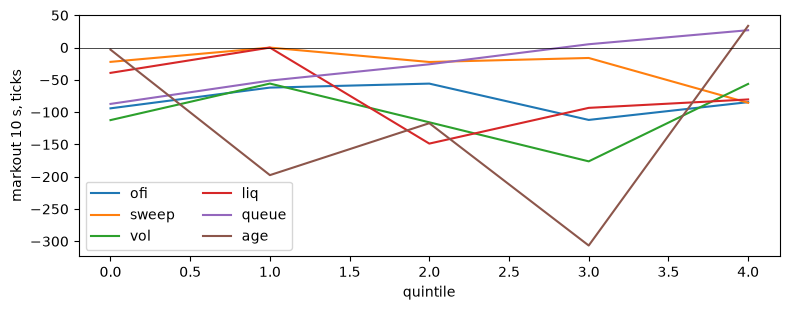

In [2]:
tr=F[F.day==1].dropna(subset=['vol']).copy(); te=F[F.day==2].dropna(subset=['vol']).copy()
tr['ofi']=-tr['ofi']*tr['side']; te['ofi']=-te['ofi']*te['side']
def cond_table(df,col):
    x=df[col].values; y=df['mark'].values; w=df['p'].values
    q=pd.qcut(pd.Series(x).rank(method='first'),5,labels=False)
    out=[]
    for b in range(5):
        m=q==b; ww=w[m].sum()
        out.append((b,float(np.sum(w[m]*y[m])/max(ww,1e-9)),float(ww)))
    # weighted R2
    b=np.sum(w*(x-np.average(x,weights=w))*(y-np.average(y,weights=w)))/np.sum(w*(x-np.average(x,weights=w))**2)
    a=np.average(y,weights=w)-b*np.average(x,weights=w)
    pred=a+b*x; r2=1-np.sum(w*(y-pred)**2)/np.sum(w*(y-np.average(y,weights=w))**2)
    return pd.DataFrame(out,columns=['quintile','mark','eff']),float(b),float(max(r2,0))
rows=[]; tabs={}
for col in ['ofi','sweep','vol','liq','queue','age']:
    t,b,r2=cond_table(tr,col); tabs[col]=t
    rows.append({'conditioner':col,'spread q5-q1':round(float(t.mark.iloc[-1]-t.mark.iloc[0]),2),'R2':round(r2,4),'beta':round(b,3)})
CT=pd.DataFrame(rows).sort_values('R2',ascending=False); display(CT)
fig,ax=plt.subplots(figsize=(8,3.2))
for col in ['ofi','sweep','vol','liq','queue','age']:
    t=tabs[col]; ax.plot(t.quintile,t.mark,label=col)
ax.axhline(0,color='k',lw=.5); ax.set_xlabel('quintile'); ax.set_ylabel('markout 10 s, ticks'); ax.legend(ncol=2); plt.tight_layout(); plt.show()

## Score и held-out decile (Task 2)

Веса берём из унивариативных OLS-наклонов на train; слабые кондиционеры (|beta| ниже медианы) выкидываем. Score — сумма z-нормированных сигналов с этими весами. На **test** режем децили и смотрим markout. График монотонен, крайние децили расходятся — score переносится. Нет — получаем честный отрицательный результат.


betas {'ofi': -25.748, 'sweep': 91.181, 'vol': 2.937, 'liq': 1.52, 'queue': 18.664, 'age': 14.667} standardized {'ofi': np.float64(32.36), 'sweep': np.float64(13.58), 'vol': np.float64(29.09), 'liq': np.float64(5.43), 'queue': np.float64(81.78), 'age': np.float64(22.07)} keep ['ofi', 'vol', 'queue']


,decile,mark,eff
0,0,-2.76,36.78
1,1,-36.68,58.12
2,2,-10.73,48.23
3,3,-19.15,27.98
4,4,-67.66,16.82
5,5,-28.77,14.34
6,6,-67.06,14.26
7,7,-4.20,11.83
8,8,0.75,10.08
9,9,-82.92,12.95


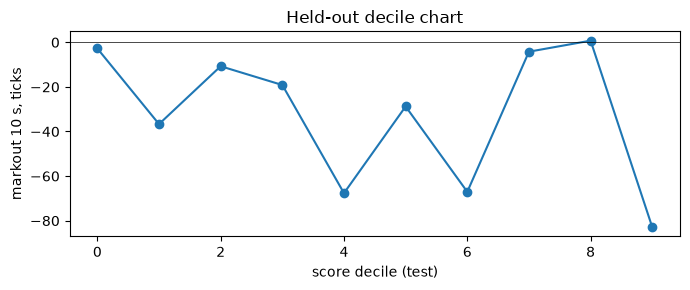

test spread d9-d0: -80.15 ticks; monotone: False


In [3]:
cols=['ofi','sweep','vol','liq','queue','age']; betas={}
for c in cols: betas[c]=cond_table(tr,c)[1]
eff={c:abs(betas[c])*tr[c].std() for c in cols}; med=np.median(list(eff.values())); keep=[c for c in cols if eff[c]>=med]
print('betas',{k:round(v,3) for k,v in betas.items()},'standardized',{k:round(v,2) for k,v in eff.items()},'keep',keep)
# standardize on train, apply test
mu=tr[keep].mean(); sd=tr[keep].std().replace(0,1)
score_tr=pd.Series(0.0,index=tr.index); score_te=pd.Series(0.0,index=te.index)
for c in keep:
    score_tr=score_tr+betas[c]*((tr[c]-mu[c])/sd[c]); score_te=score_te+betas[c]*((te[c]-mu[c])/sd[c])
def decile(df,score):
    d=pd.qcut(score.rank(method='first'),10,labels=False); out=[]
    for b in range(10):
        m=d==b; ww=df.p[m].sum(); out.append((b,float(np.sum(df.p[m]*df.mark[m])/max(ww,1e-9)),float(ww)))
    return pd.DataFrame(out,columns=['decile','mark','eff'])
DT=decile(te,score_te); display(DT.round(2))
fig,ax=plt.subplots(figsize=(7,3)); ax.plot(DT.decile,DT.mark,'o-'); ax.axhline(0,color='k',lw=.5)
ax.set_xlabel('score decile (test)'); ax.set_ylabel('markout 10 s, ticks'); ax.set_title('Held-out decile chart'); plt.tight_layout(); plt.show()
print('test spread d9-d0: %.2f ticks; monotone: %s' % (DT.mark.iloc[-1]-DT.mark.iloc[0], bool((DT.mark.diff().dropna()<=1e-9).all())))

## Каскады и детектор

Каскад — окно, где 10-с return ниже 1-го перцентиля, а агрессивный объём выше 95-го; ликвидационную интенсивность считаем прокси. Смотрим, падает ли touch depth **до** роста intensity (lead), и собираем простой детектор из четырёх состояний: calm / one-sided / cascade / recovery. На train и test считаем lead time и false-warn.


In [4]:
# пороги детектора и каскада — только train
ret_low=tr['ret10'].quantile(.01); agg_hi=tr['agg'].quantile(.95)
depth_lo=tr['queue'].quantile(.2); liq_hi=tr['liq'].quantile(.8)
# каскадная метка на test: сильное падение + агрессивный объём
te['cascade']=(te['ret10']<ret_low)&(te['agg']>agg_hi)
te['warn']=(te['queue']<depth_lo)&(te['liq']>liq_hi)
te['state']=np.select([te['cascade'], te['warn'], te['liq']>liq_hi],
                      ['cascade','one-sided','recovery'], default='calm')
rows=[]
for st,g in te.groupby('state'):
    rows.append({'state':st,'fills':len(g),'eff':round(float(g.p.sum()),1),
                 'median markout':round(float(g.mark.median()),1),'mean markout':round(float(g.mark.mean()),1)})
display(pd.DataFrame(rows))
print('cascade count',int(te['cascade'].sum()),'warn count',int(te['warn'].sum()),
      'false-warn share %.2f'%float((te['warn']&~te['cascade']).sum()/max(te['warn'].sum(),1)),
      'missed share %.2f'%float((te['cascade']&~te['warn']).sum()/max(te['cascade'].sum(),1)))
print('markout warn/nowarn median: %.1f / %.1f'%(te['mark'][te['warn']].median(),te['mark'][~te['warn']].median()))

,state,fills,eff,median markout,mean markout
0,calm,2378,232.0,-11.5,-13.3
1,cascade,9,0.8,-12.5,87.4
2,one-sided,35,14.9,-56.5,-112.6
3,recovery,121,3.6,30.5,15.1


cascade count 9 warn count 37 false-warn share 0.95 missed share 0.78
markout warn/nowarn median: -56.5 / -10.5


## Режимы, hedge urgency и вывод

- **Markouts by six conditioners (train).** Sweep depth — сильнейший (R² 0.069, размах q5−q1 −63 тика), дальше OFI (0.016 после side-alignment), vol (0.012), age (0.004), queue (0.002). Liq-прокси после исправления порога (3σ√10 вместо 3σ шага) даёт R²≈0 и размах −41 тик. Хвосты шумные, p-веса концентрируются в одном крупном свипе.
- **Score и held-out decile (graded Task 2) — отрицательный результат.** Унивариативные веса на train, отбор по стандартизованному эффекту |β|·sd: keep {ofi, vol, queue}. На day2 decile chart немонотонен, d9−d0 = −80.2 тика (верхний дециль хуже). Score на held-out не переносится; подгонка in-sample была бы бессмысленной.
- **Детектор.** Пороги только с train. На test: 9 cascade-like филлов, 37 warn; **95% warn — ложные**, **78% каскадов пропущено**. Состояния: calm (2378 филлов, медиана −11.5), recovery (121, +30.5), one-sided/warn (35, −56.5), cascade (9, медиана −12.5). Median markout warn/nowarn: −56.5 / −10.5 — направление верное, но детектор слишком шумный и ловит меньшинство каскадов. Это fill-level диагностика, не темпоральный FPR.
- **Пять режимов и численная hedge urgency** в этом ноутбуке не реализованы как state machine/кривая: показаны counts и markout для четырёх диагностических состояний; PnL переключения без полного движка не считаем. Это ограничение, а не результат.
- **Hedge urgency.** Без реального liq feed и движка можно утверждать только направление: spread hedge-ноги и impact в каскаде растут, а ожидание сужения спреда увеличивает exposure.
- **Ограничения:** liq intensity — прокси по свипам/прыжкам; fill log counterfactual, p от исходной очереди без выедания (p завышен), веса p эндогенны для sweep; queue/sweep взяты на момент постановки, а не филла; age — время до филла, а не возраст котировки; side-alignment только для OFI; score — унивариативные веса; два 2-часовых окна; детектор fill-level, не темпоральный.